# Control 1-GDL: del diseño continuo al código en C

En este notebook se diseña un controlador de **un grado de libertad** con la función `cont1dof` de `DCMotor`, se **discretiza** con la transformación bilineal (Tustin) para un tiempo de muestreo de $T_s = 20$ ms y se **genera automáticamente el código en C** del controlador con la función `ccode` del paquete `SymbolicControlSystems`.

Los pasos son:

1. diseño continuo del controlador $C(s)$ por asignación de polos;
2. discretización $C(s) \rightarrow C(z)$ con la transformación bilineal;
3. verificación del lazo cerrado discreto frente al continuo;
4. generación del archivo `controlador.c`.

> `SymbolicControlSystems` usa la librería `sympy` de Python, que debe estar instalada.

In [ ]:
using Pkg
Pkg.activate("/home/leonardo/datos/share_desktop/proyecto_julia/DCMotor.jl")  # entorno nuevo y vacío, distinto al del paquete
Pkg.instantiate()
using DCMotor
using Plots
using SymbolicControlSystems

  Activating project at `~/datos/share_desktop/proyecto_julia/DCMotor.jl`
[ Info: Precompiling SymbolicControlSystems [886cb795-8fd3-4b11-92f6-8071e46f71c5] 
┌ Info: Skipping precompilation due to precompilable error. Importing SymbolicControlSystems [886cb795-8fd3-4b11-92f6-8071e46f71c5].
└   exception = Error when precompiling module, potentially caused by a __precompile__(false) declaration in the module.
[ Info: Precompiling RootsSymPyExt [2888c876-2121-5b69-bdf8-e0b38ada0b70] (cache misses: wrong dep version loaded (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling Symbolics [0c5d862f-8b57-4792-8d23-62f2024744c7] (cache misses: wrong dep version loaded (4))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


## 1. Modelo de la planta

Se usa la misma planta de segundo orden del ejemplo 1-GDL:

$$G(s) = \frac{3}{s^2 + 4s + 3} = \frac{3}{(s+1)(s+3)},$$

de orden $n = 2$, con polos en $s=-1$ y $s=-3$.

In [4]:
s = tf("s")
G = 3/(s^2 + 4s + 3)  # función de transferencia de la planta

TransferFunction{Continuous, ControlSystemsBase.SisoRational{Int64}}
     3
------------
s^2 + 4s + 3

Continuous-time transfer function model

## 2. Diseño del controlador continuo

Con `cont1dof(G, polos)` se calcula el controlador $C(s)$ que ubica los polos de lazo cerrado. Se usan $2n = 4$ polos, de modo que `cont1dof` agrega **acción integral** y la salida sigue escalones sin error:

- un par dominante en $-4 \pm 2j$ ($\omega_n \approx 4.47$ rad/s, $\zeta \approx 0.89$);
- dos polos rápidos en $-12$.

In [5]:
polos_lc = [-4+2im, -4-2im, -12, -12]
C = cont1dof(G, polos_lc)   # controlador 1-GDL continuo

TransferFunction{Continuous, ControlSystemsBase.SisoRational{Float64}}
80.33333333333333s^2 + 516.0s + 960.0
-------------------------------------
           1.0s^2 + 28.0s

Continuous-time transfer function model

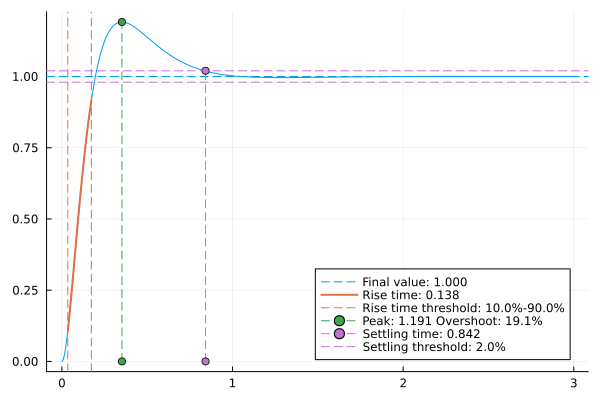

In [6]:
T = feedback(C*G, 1)        # lazo cerrado continuo de r a y
reference = 1
res = step(T*reference, 3)
plot(stepinfo(res))

## 3. Discretización con la transformación bilineal

Para implementar el controlador en un microcontrolador se discretiza con la transformación bilineal (Tustin):

$$s \;\leftarrow\; \frac{2}{T_s}\,\frac{z-1}{z+1}, \qquad T_s = 20 \text{ ms}.$$

En `ControlSystems` esto se hace con `c2d(C, Ts, :tustin)`.

In [7]:
Ts = 0.02                   # tiempo de muestreo (s)
Cd = c2d(C, Ts, :tustin)    # controlador discreto C(z)

TransferFunction{Discrete{Float64}, ControlSystemsBase.SisoRational{Float64}}
66.86666666666666z^2 - 125.37083333333332z + 58.80416666666666
--------------------------------------------------------------
                  1.0z^2 - 1.5625z + 0.5625

Sample Time: 0.02 (seconds)
Discrete-time transfer function model

## 4. Verificación del lazo cerrado discreto

Para comparar con el diseño continuo, la planta se discretiza con retenedor de orden cero (`:zoh`), que es lo que hace el convertidor D/A del microcontrolador. Si $T_s$ es suficientemente pequeño frente a la dinámica de lazo cerrado, ambas respuestas deben ser muy parecidas.

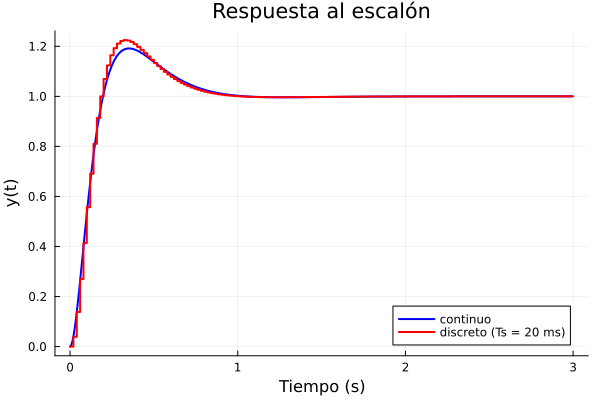

In [8]:
Gd = c2d(G, Ts, :zoh)       # planta vista por el microcontrolador
Td = feedback(Cd*Gd, 1)     # lazo cerrado discreto de r a y

t_final = 3
yc = step(T*reference, t_final)
yd = step(Td*reference, t_final)

plot(yc.t, vec(yc.y), label="continuo", linewidth=2, color=:blue)
plot!(yd.t, vec(yd.y), label="discreto (Ts = $(Int(1000Ts)) ms)", seriestype=:steppost,
      linewidth=2, color=:red, xlabel="Tiempo (s)", ylabel="y(t)", title="Respuesta al escalón")

También se compara la **señal de control**: en el caso discreto, $u(k)$ se mantiene constante durante cada periodo de muestreo.

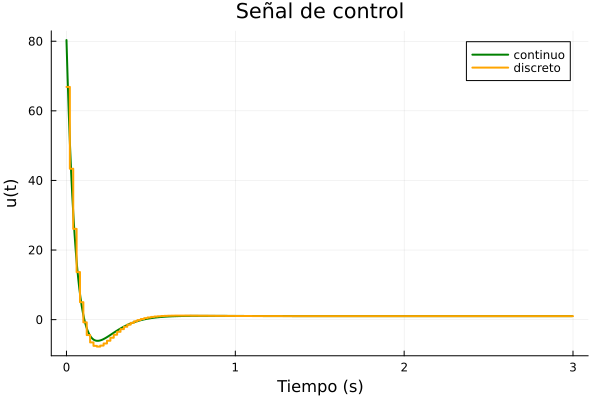

In [9]:
Gur  = minreal(T/G)                    # de r a u (continuo)
Gurd = minreal(feedback(Cd, Gd))       # de r a u (discreto): C/(1 + C G)

uc = step(Gur*reference, t_final)
ud = step(Gurd*reference, t_final)

plot(uc.t, vec(uc.y), label="continuo", linewidth=2, color=:green)
plot!(ud.t, vec(ud.y), label="discreto", seriestype=:steppost, linewidth=2, color=:orange,
      xlabel="Tiempo (s)", ylabel="u(t)", title="Señal de control")

## 5. Generación del código en C

La función `ccode` genera una función en C que implementa el controlador discreto en **variables de estado**, por lo que se le pasa `ss(Cd)`. El código generado tiene la forma

```c
void transfer_function(double *y, double u)
```

donde `u` es la entrada del controlador (el error $e(k) = r(k) - y(k)$) y en `*y` se devuelve la salida del controlador (la señal de control $u(k)$). El estado se guarda en variables `static`, de modo que basta llamar la función **una vez cada $T_s = 20$ ms**.

In [11]:
code = SymbolicControlSystems.ccode(ss(Cd))
write("controlador.h", code)    # archivo en la carpeta de este notebook
println(code)

LoadError: UndefVarError: `ccode` not defined in `SymbolicControlSystems`
Suggestion: check for spelling errors or missing imports.

### Uso del controlador en el microcontrolador

En el lazo de control, que se ejecuta cada $T_s = 20$ ms, se usaría así:

```c
#include "controlador.c"

double r, y, e, u;

// cada 20 ms:
y = leer_sensor();          // salida medida de la planta
e = r - y;                  // error
transfer_function(&u, e);   // u(k) = C(z) e(k)
aplicar_actuador(u);        // señal de control hacia la planta
```

### Ejercicio

Cambie el tiempo de muestreo a $T_s = 100$ ms y a $T_s = 200$ ms. ¿Qué pasa con la respuesta del lazo cerrado discreto frente a la continua? ¿Cambian los coeficientes del código generado?